# 60 m sprint: what running technique tells us about speed

This notebook asks one question. The men in this group are faster than the women, so once you account for that, does anything about *how* someone runs tell you how fast they are? And if it does, does it hold up for a runner the model has never seen?

Thirty university sprinters (15 men, 15 women) ran 60 m in a 17-sensor Xsens suit recorded at 60 Hz. A 31st recording, SB17, is excluded.

**How it's laid out.** Sections 1 to 4 look at the data. Section 5 tests prediction, including six hypotheses that were written down before they were computed. Section 6 checks the measurements against Xsens's own software.

**Where the numbers come from.** Every table is a sheet of `results/sprint_results.xlsx`, written by `sprint_report.py`, and every figure is drawn by a function in `sprint_outputs.py`. Set `RERUN = True` to recompute everything from the raw files (about two minutes); otherwise the saved results load in a second.

**Conventions.** Peak velocity is the top of a smoothed pelvis-speed curve (Figure 2). Joint angles are in degrees, in the side view, with knee flexion positive. They are averaged over the five strides nearest top speed and stretched onto a 0–100 % stride that starts at right-foot contact. Grey is men and orange is women; blue and red mean faster and slower. Every permutation test uses 5,000 shuffles.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sprint_pipeline as SP, sprint_report as R, sprint_outputs as OUT

RERUN = False
c, T = R.load(rerun=RERUN)
A = T["athletes"].set_index("runner_id")          # one row per runner
plt.rcParams.update(OUT.STYLE)
pd.set_option("display.width", 200, "display.max_columns", 40)

def show(sheet, n=None, cols=None):
    d = T[sheet] if cols is None else T[sheet][cols]
    display(OUT.table(d.head(n) if n else d).round(3))

## 1 · The cohort and data checks

These have to pass before anything else is read: 30 runners, no rejected strides, consistent stride timing at top speed, and one fixed reference runner (SB25: 531 frames, 8.506 m/s) that `sprint_report.py` checks every time it runs.

In [2]:
show("athletes", 5, cols=["runner_id", "sex", "height_m", "leg_m", "v_peak_ms", "v_vs_sex_ms", "t10_s", "t20_s", "t30_s"])
q = T["qa"]
print(f"Strides rejected: {q.rejected.sum()}. Largest tilt of the travel axis: {q.tilt_deg.max():.2f}°.")
print(f"Spread in stride timing at top speed: median {q.spread_top_pct.median():.0f}%, worst {q.spread_top_pct.max():.0f}%.")
OUT.table(A.groupby("sex").v_peak_ms.agg(["count", "mean", "std", "min", "max"]).rename(index=OUT.SEX_LABEL).rename_axis(None)).round(2)

,Runner,Sex,Height (m),Leg length (m),Peak velocity (m/s),Peak velocity relative to own sex's mean (m/s),10 m split time (s),20 m split time (s),30 m split time (s)
0,SB061,Men,1.80,0.98,8.855,0.154,1.848,3.041,4.178
1,SB101,Men,1.86,0.94,9.295,0.594,1.867,3.055,4.156
2,SB102,Women,1.56,0.89,7.612,0.089,2.115,3.520,4.843
3,SB110,Women,1.74,0.80,7.314,-0.209,2.112,3.542,4.917
4,SB111,Men,1.79,0.91,8.322,-0.379,1.986,3.286,4.510


Strides rejected: 0. Largest tilt of the travel axis: 0.76°.
Spread in stride timing at top speed: median 3%, worst 9%.


,Count,Mean,Std,Min,Max
Women,15,7.52,0.43,6.39,8.23
Men,15,8.70,0.40,8.10,9.35


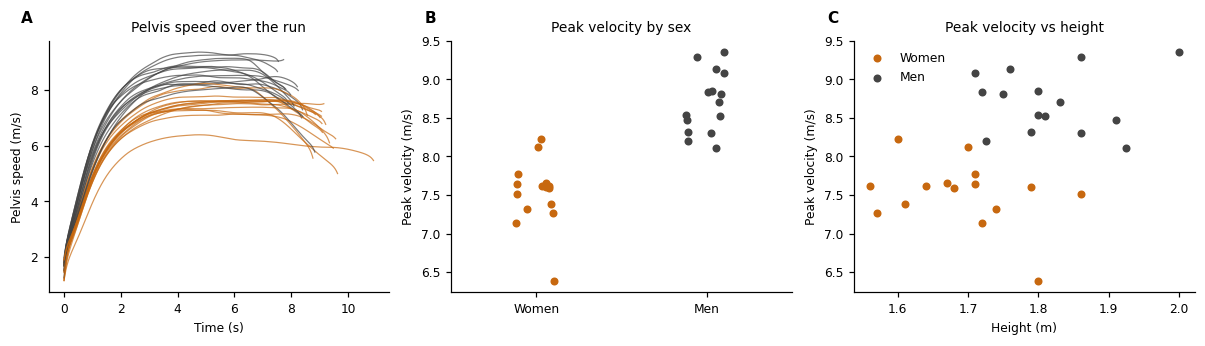

In [3]:
OUT.fig_cohort(T, c);

**Figure 1.** (A) Each runner's pelvis speed over the run. (B) Peak velocity by sex. (C) Peak velocity against height. Sex alone predicts a new runner's peak velocity with a leave-one-out R² of 0.64 (models table, Section 5). That's why the rest of the notebook keeps asking what's left once sex is accounted for.

### How the curves are smoothed

Raw marker data are noisy, and at 60 Hz one top-speed stride is only about 28 frames. Every curve is therefore smoothed with a *penalised B-spline* before anything is measured from it.

A B-spline is a sum of small, overlapping bumps (Figure 2A). Fitting one means choosing how tall each bump is so that their sum follows the data. The "penalised" part adds a cost for wiggling, so the fit follows the shape of the movement but not the frame-to-frame jitter. Joint angles use 15 bumps per stride (Figure 2B). Pelvis speed over the whole run uses 60 bumps and a stronger penalty (Figure 2C).

This matters most for peak velocity. The highest raw sample is the top of the noise, not the top of the run: across the 30 runners it sits on average 0.52 m/s above the smoothed peak. So peak velocity always comes from the smooth curve.

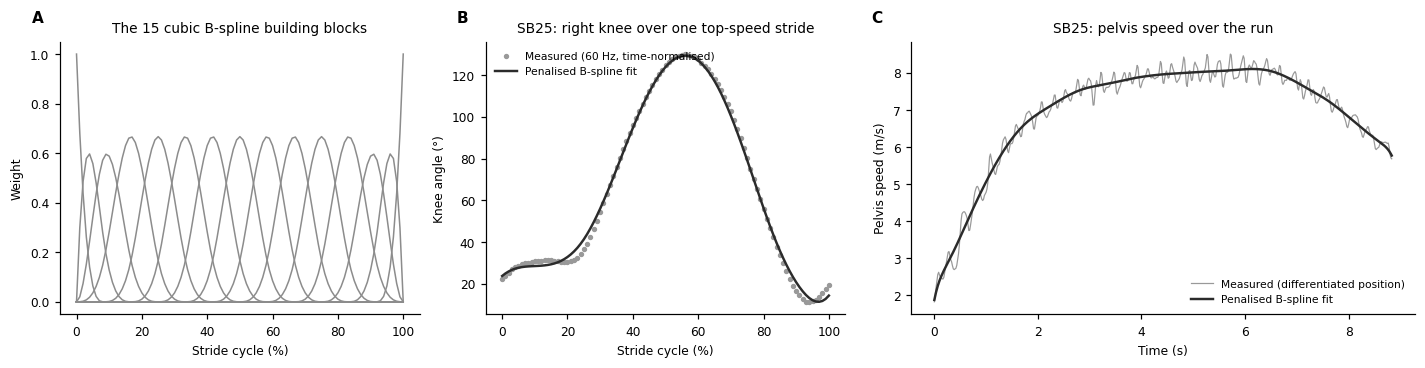

In [4]:
OUT.fig_bspline(T, c);

**Figure 2.** (A) The 15 cubic B-spline building blocks spread across the stride. (B) SB25's right knee over one top-speed stride: the measured points and the penalised fit. (C) SB25's pelvis speed over the whole run, measured and fitted.

### Body size

Taller runners have longer legs, and leg length changes some measures for reasons that have nothing to do with technique. Each measure is treated according to how it actually scales in this group. The table gives the exponent *b* from log *y* = *a* + *b*·log(leg length) + sex.

- **Joint angles** are ratios of lengths, so size doesn't affect them.
- **Step and contact timing** scale with leg length roughly as Hof (1996) predicts, so they're expressed relative to leg length ("scaled to leg length" in the tables).
- **Peak velocity and split times** don't scale with leg length within either sex, so they stay in real units. Rescaling them would add a size effect that isn't in the data.

The skeletons in the figures are drawn at a common 1.75 m height so they overlay cleanly. That is for drawing only; no number passes through it.

In [5]:
show("size")

,Variable,Exponent on leg length,"95% CI, low","95% CI, high",Expected exponent (Hof 1996),Verdict
0,Peak velocity (m/s),0.083,-0.185,0.352,0.5,size-free: keep absolute
1,10 m split time (s),0.010,-0.187,0.207,0.5,size-free: keep absolute
2,20 m split time (s),-0.004,-0.206,0.197,0.5,size-free: keep absolute
3,30 m split time (s),-0.022,-0.234,0.190,0.5,size-free: keep absolute
4,Step frequency (Hz),-0.588,-0.835,-0.340,-0.5,scales with size: use dimensionless
5,Contact time (s),0.474,-1.098,2.045,0.5,inconclusive at n = 30
6,Flight time (s),0.834,-0.216,1.885,0.5,inconclusive at n = 30


## 2 · Which measures move with peak velocity?

Every candidate measure gets one row: step and contact timing, the 22 joint-angle summaries (range of motion and average angle, for the limb that moves more and the one that moves less), and the six principal-component scores from Section 4. For each one, the table gives its correlation with peak velocity across everyone, within men, within women, and with sex held constant (partial r). The last column shows how much it improves a sex-only prediction of an unseen runner. Rows are sorted by the size of the partial correlation.

In [6]:
show("screen", 12)
s = T["screen"]
print(f"{(s.p < .05).sum()} measures correlate with peak velocity at p < .05 across everyone. "
      f"{(s.p_part < .05).sum()} still do once sex is held constant, {(s.q_part < .10).sum()} survive a false-discovery-rate correction, "
      f"and {(s.dR2_loo_vs_sex > 0.02).sum()} improve a sex-only prediction by more than 0.02.")

,Variable,n,r,p,"r, men","r, women","Partial r, sex held constant",Stride-to-stride ICC,"Partial r, corrected for reliability","95% CI, low","95% CI, high",p (partial),q (false discovery rate),Gain in LOO R² over sex
4,"Step frequency, scaled to leg length",30,0.841,0.000,0.565,0.656,0.612,NaN,NaN,0.317,0.799,0.000,0.016,0.107
5,Forward trunk lean in the first steps (°),30,0.427,0.019,0.183,0.616,0.422,NaN,NaN,0.066,0.683,0.020,0.437,0.027
42,Left hip rotation range of motion (°),30,-0.585,0.001,-0.565,-0.240,-0.404,NaN,NaN,-0.671,-0.044,0.027,0.437,0.038
35,Average right hip abduction (°),30,-0.226,0.230,-0.428,-0.343,-0.368,NaN,NaN,-0.647,-0.002,0.045,0.557,0.036
40,Left hip abduction range of motion (°),30,-0.688,0.000,-0.486,-0.188,-0.336,NaN,NaN,-0.625,0.035,0.070,0.682,0.021
48,Pelvis yaw range of motion (°),30,0.077,0.687,0.166,0.433,0.297,NaN,NaN,-0.078,0.598,0.111,0.690,0.019
39,Average left hip abduction (°),30,-0.133,0.484,-0.474,-0.180,-0.296,NaN,NaN,-0.598,0.079,0.112,0.690,0.019
33,Principal component 6 score,30,0.124,0.515,0.456,0.120,0.295,NaN,NaN,-0.080,0.597,0.113,0.690,0.018
12,"Knee range of motion, side that moves less (°)",30,-0.597,0.001,-0.456,-0.088,-0.285,0.859,-0.308,-0.590,0.091,0.127,0.690,0.010
11,"Average knee angle, side that moves more (°)",30,-0.247,0.189,-0.543,0.139,-0.274,0.484,-0.393,-0.582,0.103,0.143,0.703,-0.001


11 measures correlate with peak velocity at p < .05 across everyone. 4 still do once sex is held constant, 1 survive a false-discovery-rate correction, and 5 improve a sex-only prediction by more than 0.02.


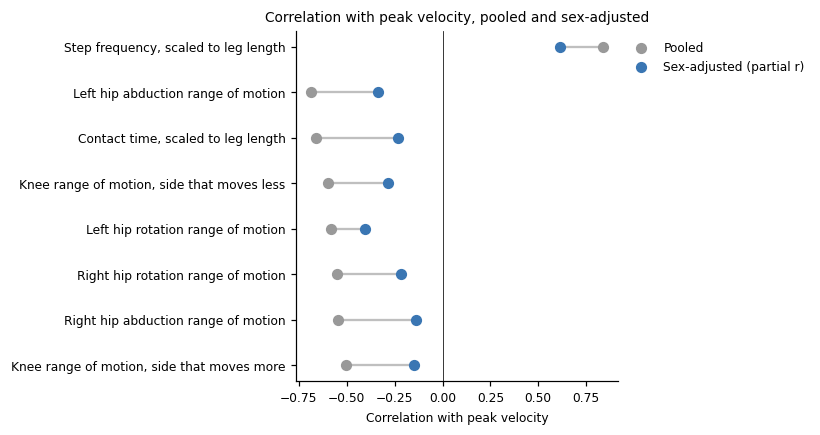

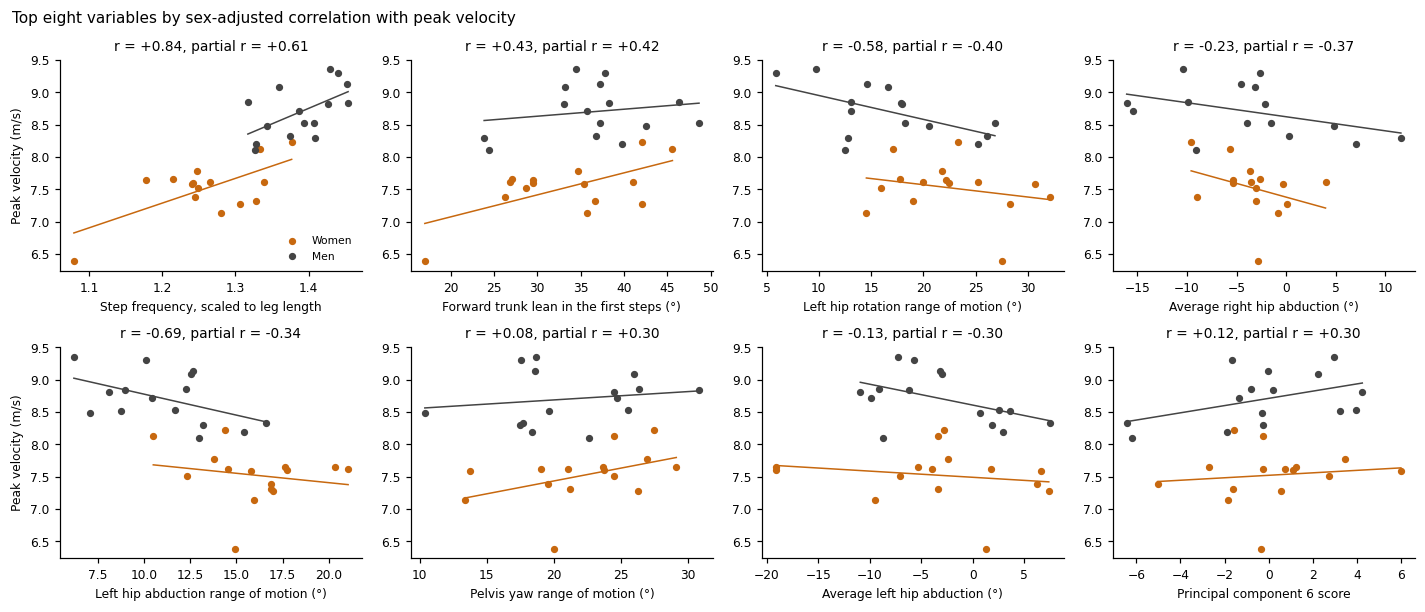

In [7]:
OUT.fig_pooled_vs_adjusted(T)
OUT.fig_screen(T);

**Figure 3.** For the eight measures most correlated with peak velocity across everyone, the grey dot is that correlation and the blue dot is what remains once sex is held constant. Most correlations shrink, because the men are both faster and different on these measures.

**Figure 4.** The eight measures with the largest correlation once sex is held constant, each against peak velocity, with a separate fit line for men and for women.

## 3 · Where in the stride does speed show up?

Instead of summarising each angle with one number, here the correlation with peak velocity is worked out at every 1 % of the stride. The dashed lines mark where a single point would reach p = .05 on its own. With 101 points some will cross by chance, so treat them as a guide only. The shaded windows come from the formal test (statistical parametric mapping, 5,000 shuffles), which was run only on the three angles chosen in advance: right knee, right hip and trunk lean.

,Outcome,Joint angle,Stride window,Peak r,Cluster mass,p
0,"Peak velocity, pooled","Knee, right",17-29 %,0.438,31.0,0.147
1,"Peak velocity, pooled","Knee, right",48-66 %,-0.541,55.0,0.058
2,"Peak velocity, pooled","Hip, right",24-46 %,0.432,54.4,0.071
3,"Peak velocity, pooled",Trunk lean,none,NaN,NaN,NaN
4,"Peak velocity, sex held constant","Knee, right",none,NaN,NaN,NaN
5,"Peak velocity, sex held constant","Hip, right",none,NaN,NaN,NaN
6,"Peak velocity, sex held constant",Trunk lean,none,NaN,NaN,NaN
7,"10 m split, sex held constant (acceleration st...","Knee, right",none,NaN,NaN,NaN
8,"10 m split, sex held constant (acceleration st...","Hip, right",5-16 %,-0.392,26.2,0.106
9,"10 m split, sex held constant (acceleration st...","Hip, right",86-100 %,-0.421,34.0,0.092


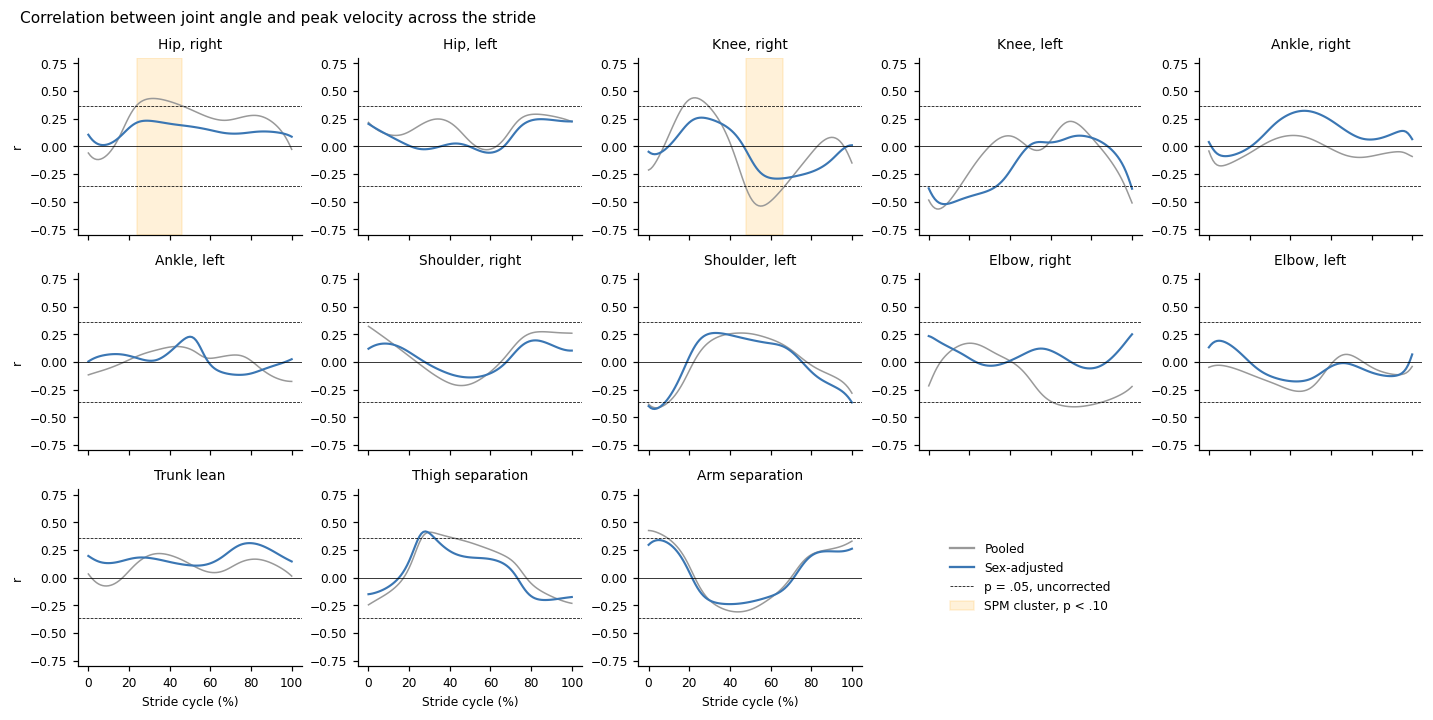

In [8]:
OUT.fig_stride_correlation(T, c)
show("spm")

**Figure 5.** Correlation between each joint angle and peak velocity through the stride: grey across everyone, blue with sex held constant. Shading marks a window where the formal test gives p < .10; none reaches p < .05. The two windows seen across everyone (right knee 48–66 %, right hip 24–46 %) disappear once sex is held constant.

## 4 · What do faster runners do differently?

Comparing the five fastest runners with the five slowest would mostly compare men with women. Instead, runners are ranked by how fast they are relative to their own sex's average, and the five at each end are compared.

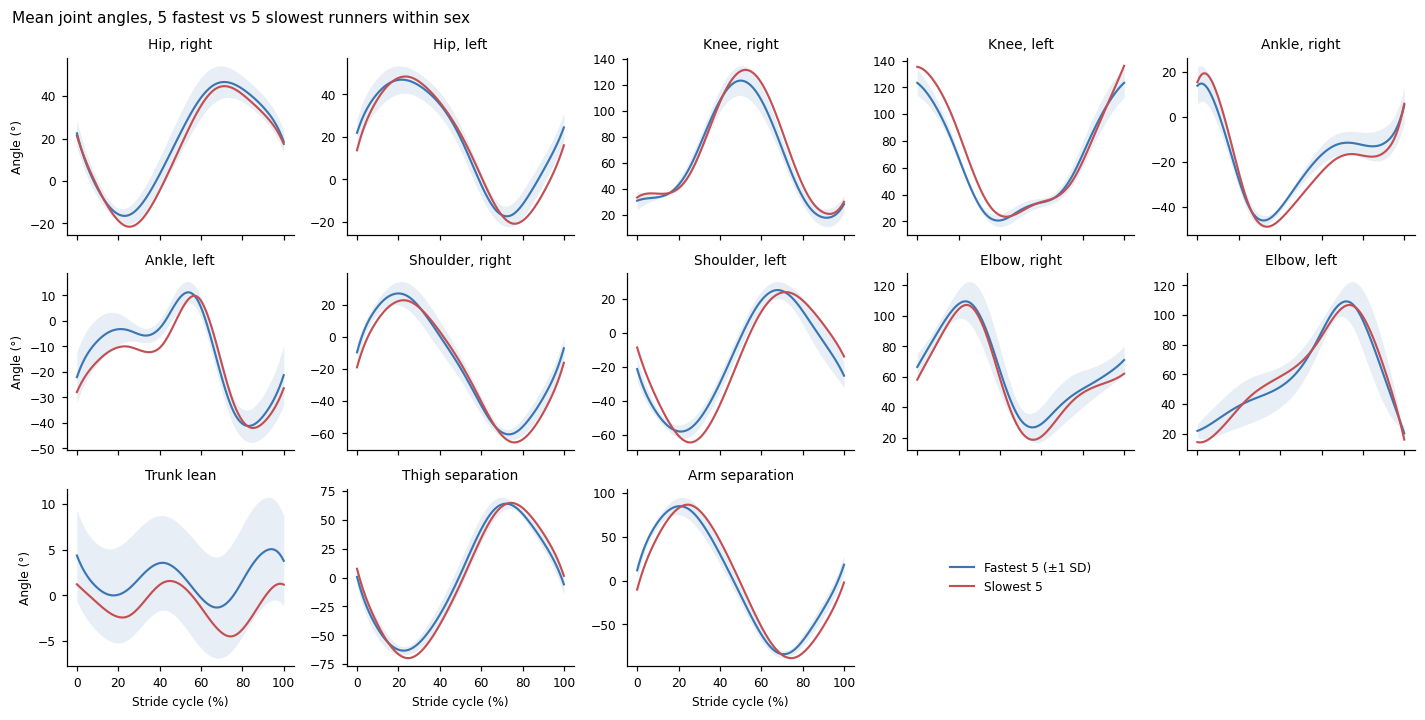

In [9]:
OUT.fig_fast_vs_slow_within_sex(T, c);

**Figure 6.** Average joint angles through the top-speed stride for the five runners who are fastest (blue) and slowest (red) relative to their own sex. The band is ±1 SD of the faster group.

### Principal components: the main ways the curves differ

Functional principal component analysis (fPCA) looks at all 13 angle curves at once and finds the few patterns along which runners differ most. Each runner then gets a score on each pattern. Before the analysis each angle is scaled to the same spread. Otherwise the knee, which moves through about 100°, would swamp the trunk, which moves through about 10°.

The first component (PC1) covers 42 % of the variation between runners, and it's mostly trunk lean, with some hip. Figure 7A–B shows what that means in practice: a runner scoring 2 SD below the mean and one scoring 2 SD above differ by about 15° of trunk lean through the whole stride.

Describing variation isn't the same as predicting speed. PC1's correlation with peak velocity is −0.18 (−0.21 with sex held constant), and models built on these scores predict an unseen runner worse than simply guessing the average (Section 5).

,Variant,Component,Variance explained (%),Cumulative variance (%),Largest loading,Largest loading's share (%),r,"Partial r, sex held constant"
0,standardised,PC1,41.988,41.988,Trunk lean,77.132,-0.177,-0.208
1,standardised,PC2,15.146,57.134,"Ankle, left",16.437,-0.175,-0.071
2,standardised,PC3,8.333,65.467,"Ankle, left",48.558,-0.107,-0.099
3,standardised,PC4,6.600,72.067,"Elbow, left",40.831,0.206,-0.145
4,standardised,PC5,5.023,77.090,"Elbow, left",39.448,0.022,0.123
5,standardised,PC6,3.430,80.520,"Ankle, right",26.118,0.124,0.295
6,unstandardised,PC1,32.008,32.008,Arm separation,23.494,-0.297,-0.221
7,unstandardised,PC2,13.678,45.686,"Elbow, left",33.368,0.188,-0.004
8,unstandardised,PC3,9.613,55.298,"Elbow, left",32.870,0.134,0.055


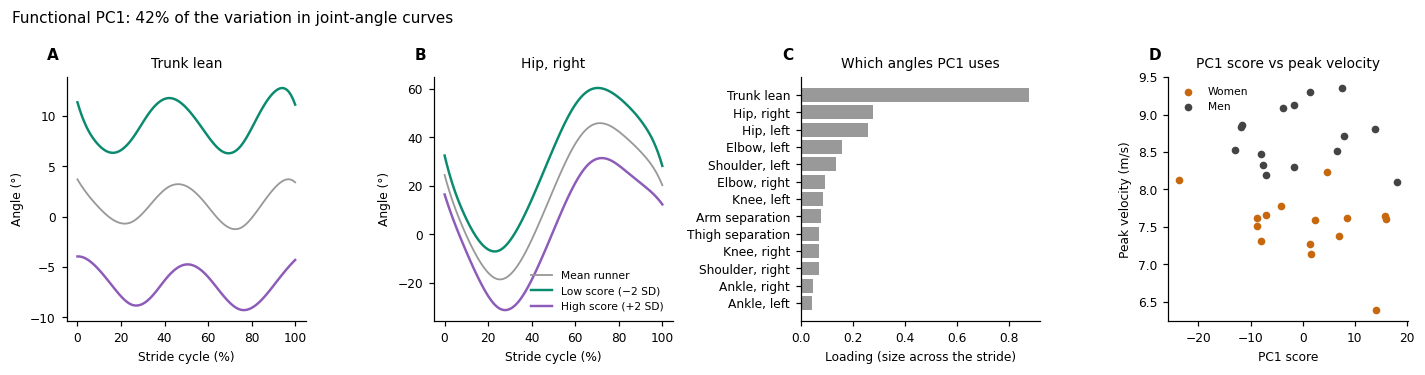

In [10]:
show("fpca")
OUT.fig_fpca(T, c);

**Figure 7.** The first functional principal component. (A, B) The two angles it uses most, drawn for an average runner (grey) and for runners 2 SD below (green) and above (purple) the mean score. (C) How much each angle contributes. (D) Each runner's score against peak velocity.

## 5 · Does any of it predict a new runner?

With 30 runners, a model can fit the data it was built on very well and still say little about the next person. So every model here is scored by leave-one-out cross-validation. It's fitted on 29 runners and asked to predict the 30th, and this is repeated for each runner in turn. The first table gives each pre-specified model's leave-one-out R² and how it compares with sex alone.

The second table shows why this matters. Each row is a common shortcut, such as choosing variables using all 30 runners and only then cross-validating. Next to it is the same step done properly, inside each fold. The 95th-percentile column is what the procedure scores when peak velocities are shuffled at random.

,Model,LOO R²,RMSE,MAE,Permutation p,Gain over sex,p (gain over sex)
0,Average only (no predictors),-0.070,0.735,0.619,NaN,-0.711,NaN
1,Sex,0.641,0.426,0.328,0.000,0.000,NaN
2,Height,0.097,0.675,0.539,0.012,-0.544,NaN
3,"Knee range of motion, both legs",0.220,0.628,0.514,0.004,-0.422,NaN
4,Knee range of motion + height,0.256,0.613,0.471,0.002,-0.385,NaN
5,Sex + knee range of motion + height,0.600,0.450,0.358,0.000,-0.041,0.398
6,All 22 angle summaries,-0.227,0.788,0.638,NaN,-0.868,NaN
7,Principal components 1–6 (right/left),-0.186,0.774,0.646,NaN,-0.828,NaN
8,Principal components 1–6 (more/less mobile side),-0.143,0.760,0.638,NaN,-0.784,NaN
9,"Principal components 1–6, unscaled angles",-0.168,0.768,0.643,NaN,-0.810,NaN


,Shortcut,Reported R²,Cross-validated R²,Overstatement,95th percentile with shuffled speeds,p
0,"Top 3 correlated measures, picked using all ru...",0.228,0.072,0.156,NaN,NaN
1,"Best of 1,540 three-measure + height models",0.403,-0.020,0.423,0.352,0.023
2,Principal components fitted on all runners (ri...,-0.223,-0.186,-0.037,NaN,NaN
3,Principal components fitted on all runners (mo...,-0.200,-0.143,-0.057,NaN,NaN
4,"Vellucci & Beaudette (2023) method, with sex",0.687,0.635,0.053,0.497,0.006
5,"Vellucci & Beaudette (2023) method, kinematics...",0.000,-0.292,0.292,0.486,1.000


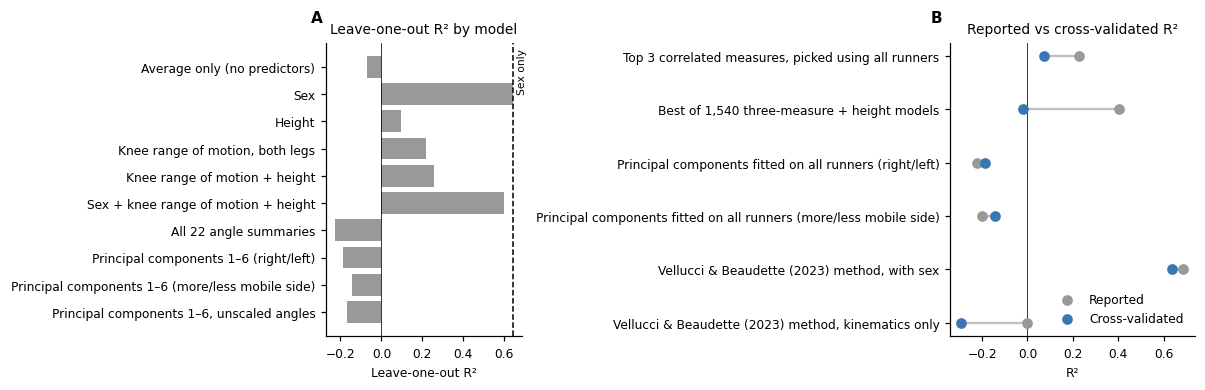

In [11]:
show("models"); show("leakage")
OUT.fig_models(T);

**Figure 8.** (A) Leave-one-out R² for each pre-specified model. The dashed line is sex alone, and no model clears it. (B) R² as each shortcut reports it (grey) and with the step refit inside each fold (blue). The search over 1,540 models drops from 0.40 to about zero.

### 5b · Acceleration: split times

The 10, 20 and 30 m split times run from first movement (the hands leaving the track) to when the pelvis has travelled that far. They're read straight from position, with no curve fitting, and match Xsens's centre-of-mass path within ±10 % for every runner (Section 6).

The predictor chosen in advance is forward trunk lean during the first steps, which earlier analyses had flagged. Its p-value comes from shuffling trunk lean within each sex, so it tests whether trunk lean adds anything beyond sex. The printed lines repeat the gain without the four runners whose acceleration strides are out of phase, and without the single most influential runner.

In [12]:
show("accel")
show("screen_accel", 8)
sex = (A.sex == "M").to_numpy(float)
ok = (T["qa"].set_index("runner_id").flag.reindex(A.index) == "ok").to_numpy()
lean = A.trunk_accel_deg.to_numpy()
top = A.t20_s.idxmax()                                   # the most influential runner (slowest split, least lean)
for m in (10, 20, 30):
    y = A[f"t{m}_s"].to_numpy()
    gain = lambda k: SP.loo_r2_fast(np.column_stack([sex[k], lean[k]]), y[k]) - SP.loo_r2_fast(sex[k], y[k])
    print(f"{m} m split, gain over sex: {gain(np.ones(30, bool)):+.3f} with everyone, "
          f"{gain(ok):+.3f} without the {(~ok).sum()} out-of-phase runners, {gain(A.index != top):+.3f} without {top}")

,Outcome,Model,LOO R²,RMSE,MAE,Permutation p,Gain over sex,p (gain over sex)
0,10 m split time (s),Average only (no predictors),-0.070,0.142,0.119,NaN,-0.709,NaN
1,10 m split time (s),Sex,0.639,0.082,0.061,0.000,0.000,NaN
2,10 m split time (s),Height,0.042,0.134,0.103,0.026,-0.597,NaN
3,10 m split time (s),Trunk lean in the first steps,0.149,0.126,0.106,0.003,-0.489,NaN
4,10 m split time (s),Sex + trunk lean in the first steps,0.740,0.070,0.054,0.000,0.102,0.001
5,10 m split time (s),"All 22 angle summaries, first steps",0.034,0.135,0.115,NaN,-0.604,NaN
6,10 m split time (s),"Principal components 1–6, first steps",-0.170,0.148,0.126,NaN,-0.808,NaN
7,20 m split time (s),Average only (no predictors),-0.070,0.249,0.210,NaN,-0.731,NaN
8,20 m split time (s),Sex,0.661,0.140,0.104,0.000,0.000,NaN
9,20 m split time (s),Height,0.054,0.234,0.179,0.022,-0.607,NaN


,Variable,n,r,p,"r, men","r, women","Partial r, sex held constant","95% CI, low","95% CI, high",p (partial),q (false discovery rate),Gain in LOO R² over sex
5,Peak velocity (m/s),30,-0.954,0.000,-0.764,-0.918,-0.850,-0.928,-0.702,0.000,0.000,0.226
4,"Step frequency, scaled to leg length",30,-0.869,0.000,-0.484,-0.789,-0.686,-0.841,-0.426,0.000,0.000,0.118
26,"Average trunk lean, first steps (°)",30,-0.519,0.003,-0.448,-0.711,-0.604,-0.795,-0.305,0.000,0.004,0.089
9,"Average hip angle, side that moves less, first...",30,-0.234,0.213,-0.839,-0.163,-0.492,-0.728,-0.154,0.006,0.040,0.068
19,"Average shoulder angle, side that moves more, ...",30,-0.262,0.162,-0.297,-0.512,-0.424,-0.684,-0.067,0.020,0.110,0.028
24,"Elbow range of motion, side that moves less, f...",30,0.215,0.255,0.414,0.350,0.373,0.007,0.650,0.043,0.199,0.007
21,"Average shoulder angle, side that moves less, ...",30,0.304,0.103,0.386,0.333,0.352,-0.017,0.636,0.056,0.226,0.027
27,"Trunk lean range of motion, first steps (°)",30,0.387,0.034,0.212,0.430,0.336,-0.035,0.626,0.069,0.226,0.017


10 m split, gain over sex: +0.102 with everyone, +0.118 without the 4 out-of-phase runners, +0.053 without SB202
20 m split, gain over sex: +0.089 with everyone, +0.104 without the 4 out-of-phase runners, +0.044 without SB202
30 m split, gain over sex: +0.072 with everyone, +0.085 without the 4 out-of-phase runners, +0.030 without SB202


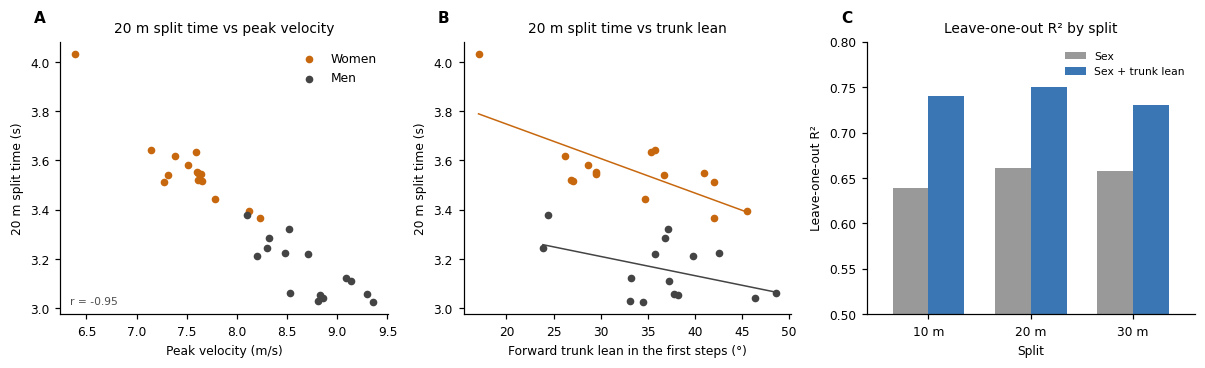

In [13]:
OUT.fig_splits(T);

**Figure 9.** (A) 20 m split time against peak velocity: the runners who are fastest at top speed also accelerate fastest. (B) 20 m split time against forward trunk lean in the first steps, with a separate fit for men and women. (C) Leave-one-out R² for sex alone and for sex plus trunk lean, at each split.

### 5c · Six hypotheses written down in advance

These six went into the README, with the direction each was expected to go, before any of them was computed. Each uses data already recorded.

| | Measure | Outcome |
|---|---|---|
| H1 | Thigh retraction velocity | Peak velocity |
| H2 | Knee extension velocity | Peak velocity |
| H3 | Touchdown distance (how far ahead of the pelvis the foot lands) | Peak velocity |
| H4 | Shank angle at touchdown | 10 m split |
| H5 | Arm–leg relative phase (coordination) | Peak velocity |
| H6 | Hamstring lengthening velocity in late swing (OpenSim) | Peak velocity |

L1 to L4 are leads from earlier analyses: forward trunk lean in the first steps, for each split, and step frequency scaled to leg length. They're judged by the same rule.

A hypothesis counts as **supported** only if all of these hold: the Holm-corrected p is below .05; the effect goes in the predicted direction; it improves on sex alone; the improvement is still at least 0.03 after removing the single most influential runner; and its bootstrap 95 % interval excludes zero. A measure is called **not measurable at 60 Hz** if more than 10 % of runners get physically impossible values.

,ID,Outcome,Variable,n,Predicted direction,"Partial r, sex held constant","95% CI, low","95% CI, high","r, men","r, women",Gain in LOO R² over sex,p (gain),p (Holm),Gain without the most influential runner,Most influential runner,"Bootstrap 95% CI, low","Bootstrap 95% CI, high",Implausible values,Verdict
0,H1,Peak velocity (m/s),Thigh retraction velocity (°/s),30,+,0.173,-0.206,0.508,-0.089,0.371,-0.011,0.359,1.000,-0.017,SB15,-0.047,0.023,0,not supported
1,H2,Peak velocity (m/s),Knee extension velocity (°/s),30,+,0.105,-0.272,0.454,-0.028,0.261,-0.053,0.996,1.000,-0.068,SB112,-0.141,0.003,0,not supported
2,H3,Peak velocity (m/s),Touchdown distance (m),30,-,-0.083,-0.443,0.299,-0.108,-0.059,-0.043,0.904,1.000,-0.057,SB202,-0.114,0.003,17,not measurable at 60 Hz (QA: implausible values)
3,H4,10 m split time (s),Shank angle at touchdown (°),30,-,-0.476,-0.717,-0.132,-0.470,-0.486,0.042,0.015,0.074,0.018,SB25,-0.081,0.166,0,"hypothesis-generating, not robust"
4,H5,Peak velocity (m/s),Arm–leg relative phase (°),30,either,0.357,-0.011,0.640,0.444,0.317,0.031,0.032,0.126,-0.012,SB161,-0.038,0.117,0,"hypothesis-generating, not robust"
5,H6,Peak velocity (m/s),"Hamstring lengthening velocity, late swing (le...",25,+,0.153,-0.266,0.524,0.238,-0.056,-0.011,0.358,0.358,-0.020,SB73,-0.053,0.016,0,not supported
6,L1,10 m split time (s),Forward trunk lean in the first steps (°),30,-,-0.617,-0.802,-0.324,-0.451,-0.736,0.102,0.000,NaN,0.053,SB202,-0.028,0.277,0,"hypothesis-generating, not robust"
7,L2,20 m split time (s),Forward trunk lean in the first steps (°),30,-,-0.604,-0.795,-0.305,-0.448,-0.711,0.089,0.000,NaN,0.044,SB202,-0.034,0.249,0,"hypothesis-generating, not robust"
8,L3,30 m split time (s),Forward trunk lean in the first steps (°),30,-,-0.572,-0.776,-0.260,-0.396,-0.686,0.072,0.001,NaN,0.030,SB202,-0.049,0.225,0,"hypothesis-generating, not robust"
9,L4,Peak velocity (m/s),"Step frequency, scaled to leg length",30,+,0.612,0.317,0.799,0.565,0.656,0.107,0.001,NaN,0.037,SB202,-0.051,0.304,0,"hypothesis-generating, not robust"


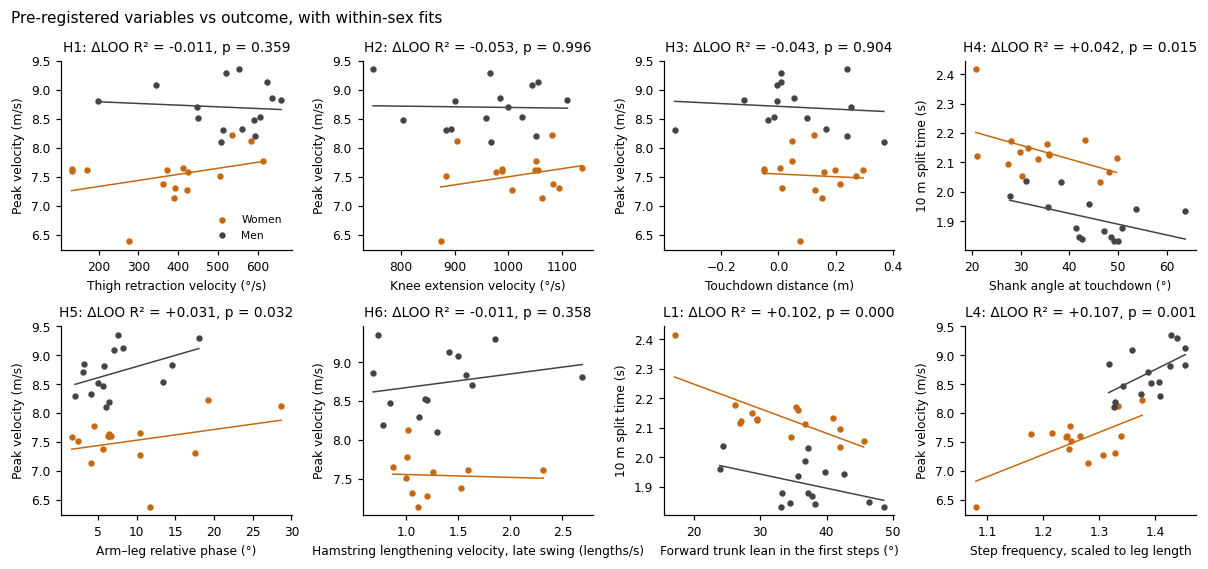

In [14]:
show("prespecified", cols=["id", "target", "variable", "n", "predicted_sign", "r_part", "r_part_lo", "r_part_hi", "r_M", "r_F",
                           "dR2", "p_gain", "p_holm", "dR2_min_drop1", "most_influential", "boot_lo", "boot_hi", "n_implausible", "verdict"])
OUT.fig_prespecified(T);

**Figure 10.** Each pre-registered measure (H1–H6) and earlier lead (L1, L4) against its outcome, with separate fits for men and women. Panel titles give the gain over sex in leave-one-out R² and its p-value. None meets the rule above. H4, H5 and the leads are worth following up, but for each one either a single runner (usually SB202) carries most of the gain or the bootstrap interval includes zero.

### Within each runner: a step-by-step model

Everything above compares runners with each other. This looks inside each run instead. Every step of every run (about 1,000 in all) goes into a mixed model of step speed, with a separate baseline for each runner. Trunk lean and step frequency are each split into two parts: how a runner changes as they speed up (within), and who leans more or steps faster overall (between). This analysis is exploratory.

In [15]:
show("steps_mixed")

,Model,Term,Estimate,"95% CI, low","95% CI, high",p,Steps,Runners
0,Random intercept,Intercept,4.442,2.656,6.227,0.000,1022,30
1,Random intercept,"Trunk lean, within a runner (m/s per °)",-0.074,-0.076,-0.072,0.000,1022,30
2,Random intercept,"Trunk lean, between runners (m/s per °)",0.029,0.005,0.053,0.019,1022,30
3,Random intercept,"Step frequency, within a runner (m/s per Hz)",0.396,0.335,0.456,0.000,1022,30
4,Random intercept,"Step frequency, between runners (m/s per Hz)",0.537,0.098,0.976,0.016,1022,30
5,Random intercept,Men vs women (m/s),0.823,0.586,1.060,0.000,1022,30
6,Random slope,Spread of runners' trunk-lean slopes (SD),0.015,NaN,NaN,NaN,1022,30
7,Random slope,"Runner's slope vs peak velocity, sex held cons...",-0.382,NaN,NaN,0.037,1022,30
8,Random slope,"Runner's slope vs 10 m split, sex held constan...",0.024,NaN,NaN,0.898,1022,30


### 5d · Muscle–tendon lengths (OpenSim)

For each runner, `sprint_opensim.py` scales the OpenSim gait2392 model to their height, runs inverse kinematics, and records how each muscle–tendon unit lengthens and shortens over the top-speed stride. This describes stretch, not muscle activity. Activity would need force plates, body mass and EMG, none of which were recorded.

Five of the 30 runners are left out because their inverse-kinematics fit failed the quality check (knee or hip r below 0.95 against this pipeline, or marker error above 35 mm).

Inverse kinematics passed for 0 runners; failed for SB111, SB16, SB202, SB91, SB92.


,Variable,n,r,"r, men","r, women","Partial r, sex held constant",p (partial),q (false discovery rate),Gain in LOO R² over sex
10,Medial gastrocnemius peak lengthening velocity...,25,-0.014,-0.351,-0.027,-0.282,0.172,0.996,-0.019
9,Medial gastrocnemius excursion (% of length),25,-0.165,-0.300,-0.134,-0.259,0.212,0.996,-0.004
13,"Hamstrings, share of muscle–tendon excursion (%)",25,0.158,0.467,-0.512,0.252,0.224,0.996,-0.015
12,Soleus peak lengthening velocity (lengths/s),25,-0.068,-0.422,0.307,-0.244,0.240,0.996,-0.022
11,Soleus excursion (% of length),25,-0.143,-0.427,0.212,-0.234,0.259,0.996,-0.005
16,"Adductors, share of muscle–tendon excursion (%)",25,-0.053,-0.349,0.088,-0.188,0.368,0.996,-0.017
4,Gluteus maximus peak lengthening velocity (len...,25,0.008,0.083,0.351,0.174,0.405,0.996,-0.005
2,"Hamstring lengthening velocity, late swing (le...",25,0.122,0.238,-0.056,0.153,0.464,0.996,-0.011


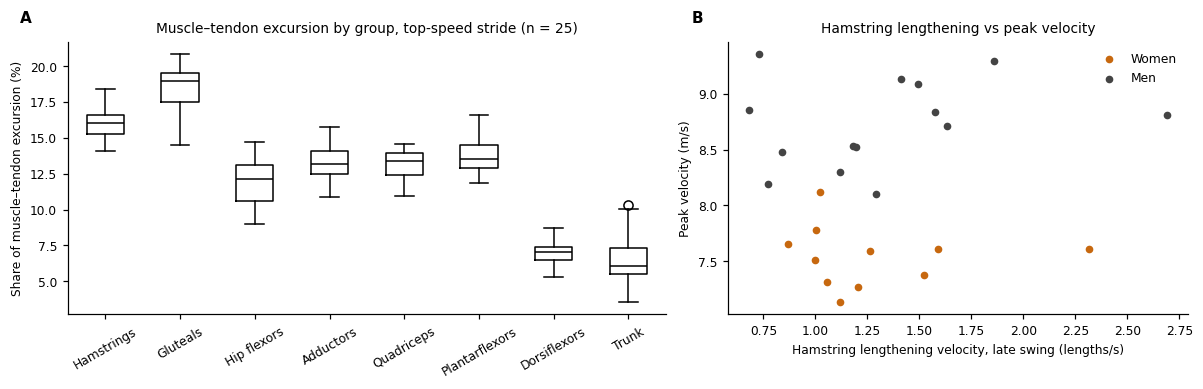

In [16]:
mt = T["muscle_mtu"].set_index("runner_id")
print(f"Inverse kinematics passed for {(mt.ik_qa == 'pass').sum()} runners; failed for {', '.join(mt.index[mt.ik_qa == 'fail'])}.")
show("screen_mtu", 8, cols=["variable", "n", "r", "r_M", "r_F", "r_part_sex", "p_part", "q_part", "dR2_loo_vs_sex"])
OUT.fig_mtu(T);

**Figure 11.** (A) Each muscle group's share of the body's total muscle–tendon stretch over the top-speed stride (25 runners). (B) Hamstring lengthening velocity in late swing against peak velocity (H6).

## 6 · Are the measurements trustworthy?

Three checks.

**Consistency.** The first table shows how consistent the 22 angle summaries are from stride to stride (ICC) as more strides are averaged. Five strides around top speed is the sweet spot. Reaching further back into the acceleration phase makes them less consistent, not more.

**Joint-angle definitions.** The second table compares each runner's OpenSim joint angles with this pipeline's. The knee agrees closely. The hip is offset because the two define it differently: thigh against trunk here, thigh against pelvis in OpenSim.

**Agreement with Xsens.** The third table compares the pipeline with Xsens's own exported results, frame by frame, against fixed tolerances: an exact match for counts of files and frames, ±10 % for times and speeds, and ±1 for numbers of foot contacts. The design follows Cotton and Leonard (2026). Xsens uses the same sensors, so passing means the processing agrees with the manufacturer's model. It can't show that the suit itself is accurate; that would need force plates, timing gates or video, which this dataset doesn't have.

In [17]:
show("reliability")
show("muscle_mtu", 6, cols=["runner_id", "ik_rms_mm", "knee_R_r_osim", "hip_R_r_osim", "hip_R_offset_osim_deg", "ik_qa"])

,Strides pooled,Strides per runner,Median ICC,Variables with ICC > 0.75,Variables with ICC < 0.50,Mean speed (% of peak)
0,5,150,0.802,16,1,99.385
1,8,240,0.710,7,5,98.958
2,10,300,0.640,1,5,98.356
3,all,497,0.359,0,12,91.625


,Runner,IK marker error (mm),"Right knee, r vs OpenSim","Right hip, r vs OpenSim",Right hip offset vs OpenSim (°),IK quality check
0,SB061,29.005,0.990,0.973,-38.74,ok
1,SB101,22.472,0.994,0.978,-25.45,ok
2,SB102,28.789,0.989,0.950,-32.17,ok
3,SB110,24.987,0.999,0.983,7.05,ok
4,SB111,25.584,0.732,0.951,-36.71,fail
5,SB112,25.499,0.997,0.983,-21.74,ok


In [18]:
show("eval", cols=["category", "task", "value", "tolerance", "n", "pass_rate", "detail"])
T["eval"].dropna(subset=["pass_rate"]).groupby("category", sort=False).pass_rate.mean().round(3).to_frame("Average pass rate")

,Category,Check,Value,Tolerance,n,Pass rate,Detail
0,database,C3D trials on disk,31,= 31,1,1.000,
1,database,Xsens xlsx export for every C3D,31,= 31,1,1.000,
2,database,runners analysed (SB17 excluded),30,= 30,1,1.000,
3,database,C3D frames = xlsx frames,30,exact,30,1.000,
4,database,SB25 invariant,"531 fr, 8.506 m/s","531 fr, 8.506 m/s",1,1.000,
5,spatiotemporal,Peak velocity vs Xsens centre of mass peak,0.04,±10 %,30,1.000,"bias +0.04 m/s, LoA -0.30 to +0.38; r = 0.977"
6,spatiotemporal,top-speed stride time vs Xsens foot-speed cont...,0.0062,±10 %,30,0.967,bias +6.2 ms
7,spatiotemporal,10 m split vs Xsens centre of mass path,-0.009,±10 %,30,1.000,"bias -9 ms, r = 0.999"
8,spatiotemporal,20 m split vs Xsens centre of mass path,-0.011,±10 %,30,1.000,"bias -11 ms, r = 0.999"
9,spatiotemporal,30 m split vs Xsens centre of mass path,-0.012,±10 %,30,1.000,"bias -12 ms, r = 0.999"


,Average pass rate
category,
database,1.000
spatiotemporal,0.993
segmentation,0.517
classification (2AFC),0.767
kinematics,0.992
domain ranges,0.400


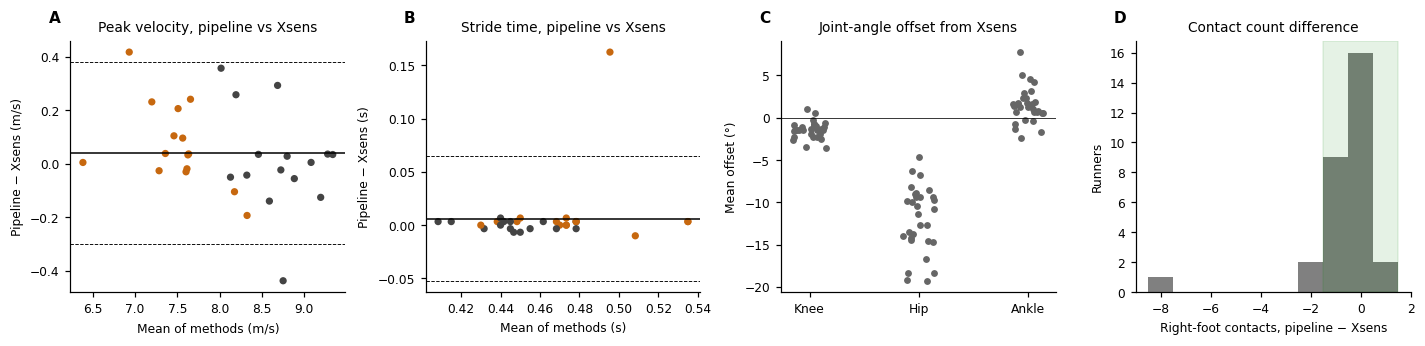

In [19]:
OUT.fig_agreement(T);

**Figure 12.** (A, B) Bland–Altman plots of the pipeline against Xsens for peak velocity and stride time. The solid line is the average difference and the dashed lines are the 95 % limits of agreement. (C) Each runner's average joint-angle offset from Xsens; the hip offset is the definition difference described above. (D) Difference in the number of right-foot contacts detected; the shaded band is ±1.

### Contact time

A foot contact lasts only five or six frames at 60 Hz, so how contact is defined changes the answer. The heel–toe height band was chosen as the main definition before any results were seen; the others are sensitivity checks. Definitions are judged only on criteria that don't involve speed: how many runners fall in the 80–140 ms range typical of trained sprinters, how consistent it is from stride to stride, and how many frames a contact spans. Picking a definition because it correlates best with speed would be the same mistake Figure 8B shows.

In [20]:
show("contact_defs", cols=["definition", "role", "mean_ms", "sd_ms", "pct_runners_80_140ms", "icc_stride", "frames_per_contact"])
show("contact_robustness", cols=["id", "variable", "r_part", "dR2", "p_gain", "dR2_min_drop1", "boot_lo", "boot_hi"])

,Definition,Role,Mean (ms),SD (ms),Runners within 80–140 ms (%),Stride-to-stride ICC,Frames per contact
0,Heel–toe height band,ANALYSIS,95.667,32.331,66.667,0.541,5.740
1,Foot-centre height band,sensitivity,66.222,13.412,20.000,0.342,3.973
2,Contact-point speed threshold,sensitivity,89.459,23.069,63.333,0.423,5.368
3,Flight-time (ballistic) model,sensitivity,113.556,21.707,86.667,0.363,6.813
4,"Contact-point threshold, 0.5 m/s",threshold sweep,34.404,15.241,0.000,0.349,2.064
5,"Contact-point threshold, 1 m/s",threshold sweep,63.911,19.793,23.333,0.285,3.835
6,"Ballistic model, 1 mm threshold",threshold sweep,147.778,23.281,36.667,0.386,8.867
7,"Ballistic model, 3 mm threshold",threshold sweep,93.889,19.320,80.000,0.421,5.633
8,"Ballistic model, 5 mm threshold",threshold sweep,72.889,19.253,33.333,0.532,4.373
9,Xsens foot-speed contacts,threshold sweep,18.111,20.374,0.000,0.617,1.087


,ID,Variable,"Partial r, sex held constant",Gain in LOO R² over sex,p (gain),Gain without the most influential runner,"Bootstrap 95% CI, low","Bootstrap 95% CI, high"
0,C1,"Contact time, heel–toe height band (s)",-0.215,-0.024,0.701,-0.036,-0.100,0.038
1,C2,"Contact time, foot-centre height band (s)",-0.040,-0.016,0.488,-0.026,-0.031,-0.005
2,C3,"Contact time, contact-point speed threshold (s)",-0.423,0.029,0.038,0.008,-0.119,0.148
3,C4,"Contact time, flight-time (ballistic) model (s)",-0.377,0.027,0.041,0.007,-0.054,0.117


### What the checks show

1. **The files and joint angles line up.** All 31 recordings have a matching Xsens export with the same number of frames. The knee curve matches Xsens almost exactly (r ≈ 1.00, about 1.4° offset). The hip sits about 12° from Xsens because of the definition difference, not an error.
2. **Peak velocity holds up.** It is within ±10 % of Xsens's centre-of-mass peak for all 30 runners (average difference +0.04 m/s), and the two agree on which of any two runners is faster 93 % of the time.
3. **Foot-contact timing is the weakest measure.** The number of contacts is within ±1 for 27 of 30 runners, but contact duration ranges from 66 to 114 ms depending on the definition, and landing position is uncertain by about ±0.14 m per frame. That is why H3 can't be measured.
4. **Sex can't be guessed from the joint-angle summaries** (leave-one-out accuracy 0.57, p = .29). Sex predicts speed directly, not through a recognisably male or female running style.